# ATL08 v6 metadata analysis and mapping of processed, filtered, & extracted covar tiled parquets


In [1]:
import matplotlib.pyplot as plt
import matplotlib
import geopandas as gpd
import pandas as pd
import s3fs

In [2]:
ICESAT2_BOREAL_REPO_PATH = '/projects/code/icesat2_boreal'               #'/projects/icesat2_boreal' # /projects/Developer/icesat2_boreal/lib
ICESAT2_BOREAL_LIB_PATH = ICESAT2_BOREAL_REPO_PATH + '/lib'
import sys, os
import glob

sys.path.append(ICESAT2_BOREAL_LIB_PATH)
import CovariateUtils
import maplib_folium
import mosaiclib
from mosaiclib import *
import extract_atl08_covars

from pathlib import Path
import importlib
import folium
#import contextily as ctx

NASA MAAP


In [3]:
import time

In [4]:
import importlib
import mosaiclib
importlib.reload(mosaiclib)
from mosaiclib import *

In [5]:
HLS_TINDEX_FN_DICT
z = pd.read_csv('s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2024/HLS_tindex_master.csv')
z.shape

(4960, 6)

In [6]:
#pip install lonboard

## Part 1: Read Boreal Tile Geopackage w/ locations of tiles

For now, we read in the existing geopackage from the earlier version.  Read the geopackage in as a geopandas dataframe.

In [7]:
# Boreal Tiles 
boreal_tiles_model_ready_fn = '/projects/shared-buckets/montesano/databank/boreal_tiles_v004_model_ready.gpkg'
boreal_tiles = gpd.read_file(boreal_tiles_model_ready_fn)

In [8]:
len(boreal_tiles)

4956

### Build tindex of ATL08 filt 30m extract covars

In [39]:
YEAR_ATL08 = 2024
FROM_EXTRACT_COVARS = True

In [40]:
DICT_BUILD_TINDEX_ATL08_FILT = {
    'SET': 'ATL08',
    'USER': 'montesano',
    'ALG_NAME': 'process_atl08_boreal',
    'ALG_VERSION': 'process_atl08_boreal',
    'VAR': 'ATL08_filt',
    'BATCH_NAME': f'030m/{YEAR_ATL08}',
    'YEAR': 2024,
    'DPS_MONTH_LIST': '11',
    'DPS_DAY_MIN': 1,
    'TILES_INDEX_PATH': '/projects/shared-buckets/montesano/databank/boreal_tiles_v004_model_ready.gpkg'
}

if FROM_EXTRACT_COVARS:
    DICT_BUILD_TINDEX_ATL08_FILT['ALG_NAME'] = 'run_extract_atl08_covars'
    DICT_BUILD_TINDEX_ATL08_FILT['ALG_VERSION'] = 'extract_atl08_covars'
    DICT_BUILD_TINDEX_ATL08_FILT['VAR'] = 'ATL08_filt_extract'
    DICT_BUILD_TINDEX_ATL08_FILT['BATCH_NAME'] = f'{YEAR_ATL08}'

DICT_BUILD_TINDEX = DICT_BUILD_TINDEX_ATL08_FILT


DICT_BUILD_TINDEX

{'SET': 'ATL08',
 'USER': 'montesano',
 'ALG_NAME': 'run_extract_atl08_covars',
 'ALG_VERSION': 'extract_atl08_covars',
 'VAR': 'ATL08_filt_extract',
 'BATCH_NAME': '2024',
 'YEAR': 2024,
 'DPS_MONTH_LIST': '11',
 'DPS_DAY_MIN': 1,
 'TILES_INDEX_PATH': '/projects/shared-buckets/montesano/databank/boreal_tiles_v004_model_ready.gpkg'}

In [41]:
%%time

DPS_IDENTIFIER = f"{DICT_BUILD_TINDEX['ALG_VERSION']}/{DICT_BUILD_TINDEX['BATCH_NAME']}"
#DPS_IDENTIFIER = f"{DICT_BUILD_TINDEX['ALG_VERSION']}"
OUTDIR = f"/projects/my-public-bucket/DPS_tile_lists/{DICT_BUILD_TINDEX['SET']}/{DPS_IDENTIFIER}"
!mkdir -p $OUTDIR

# Build tindex
args = f"--RETURN_DUPS --user {DICT_BUILD_TINDEX['USER']} --dps_identifier {DPS_IDENTIFIER} \
-alg_name {DICT_BUILD_TINDEX['ALG_NAME']} -t {DICT_BUILD_TINDEX['VAR']} -y {DICT_BUILD_TINDEX['YEAR']} \
--dps_month_list {DICT_BUILD_TINDEX['DPS_MONTH_LIST']} -d_min {DICT_BUILD_TINDEX['DPS_DAY_MIN']} --outdir {OUTDIR} \
-boreal_tile_index_path {DICT_BUILD_TINDEX['TILES_INDEX_PATH']}"

if DICT_BUILD_TINDEX['ALG_VERSION'] == 'process_atl08_boreal':
    args += ' --SLIDERULE_OUT'
print(args)

!time python /projects/code/icesat2_boreal/lib/build_tindex_master.py $args #--WRITE_TINDEX_MATCHES_GDF

--RETURN_DUPS --user montesano --dps_identifier extract_atl08_covars/2024 -alg_name run_extract_atl08_covars -t ATL08_filt_extract -y 2024 --dps_month_list 11 -d_min 1 --outdir /projects/my-public-bucket/DPS_tile_lists/ATL08/extract_atl08_covars/2024 -boreal_tile_index_path /projects/shared-buckets/montesano/databank/boreal_tiles_v004_model_ready.gpkg
NASA MAAP
INFO: Pandarallel will run on 25 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.
NASA MAAP

Building a list of tiles:
DPS ID:		extract_atl08_covars/2024
Type:		ATL08_filt_extract
Year:		['2024']
Month:		['11']
Days:		1-31

Output dir:  /projects/my-public-bucket/DPS_tile_lists/ATL08/extract_atl08_covars/2024
Multiprocessing n obs with pandarallel...
Rows before NaN removal: 36
Paths creating null tile_nums: []
Rows after NaN removal: 36

No duplicates found.

# of duplicate tiles: 0
Final # of tiles: 36
Writing duplicates csv: /projects/my-public-bucket/DPS_tile_lists

In [34]:
z = pd.read_csv('s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/ATL08/extract_atl08_covars/2024/ATL08_filt_extract_tindex_master.csv')
z

,index,s3_path,local_path,file,tile_num,n_obs,creation time
0,0,s3://maap-ops-workspace/montesano/dps_output/r...,/projects/my-private-bucket/dps_output/run_ext...,atl08_006_030m_2024_2024_06_09_filt_covars_001...,1323,4605,2024-11-19 10:57:25
1,1,s3://maap-ops-workspace/montesano/dps_output/r...,/projects/my-private-bucket/dps_output/run_ext...,atl08_006_030m_2024_2024_06_09_filt_covars_001...,1329,9068,2024-11-19 10:57:24
2,2,s3://maap-ops-workspace/montesano/dps_output/r...,/projects/my-private-bucket/dps_output/run_ext...,atl08_006_030m_2024_2024_06_09_filt_covars_001...,1328,7871,2024-11-19 10:57:21
3,3,s3://maap-ops-workspace/montesano/dps_output/r...,/projects/my-private-bucket/dps_output/run_ext...,atl08_006_030m_2024_2024_06_09_filt_covars_001...,1326,9083,2024-11-19 10:57:17
4,4,s3://maap-ops-workspace/montesano/dps_output/r...,/projects/my-private-bucket/dps_output/run_ext...,atl08_006_030m_2024_2024_06_09_filt_covars_001...,1392,9831,2024-11-19 10:57:09
5,5,s3://maap-ops-workspace/montesano/dps_output/r...,/projects/my-private-bucket/dps_output/run_ext...,atl08_006_030m_2024_2024_06_09_filt_covars_001...,1265,19415,2024-11-19 10:57:01
6,6,s3://maap-ops-workspace/montesano/dps_output/r...,/projects/my-private-bucket/dps_output/run_ext...,atl08_006_030m_2024_2024_06_09_filt_covars_001...,1333,15895,2024-11-19 10:56:57
7,7,s3://maap-ops-workspace/montesano/dps_output/r...,/projects/my-private-bucket/dps_output/run_ext...,atl08_006_030m_2024_2024_06_09_filt_covars_001...,1325,11435,2024-11-19 10:56:55
8,8,s3://maap-ops-workspace/montesano/dps_output/r...,/projects/my-private-bucket/dps_output/run_ext...,atl08_006_030m_2024_2024_06_09_filt_covars_001...,1334,20054,2024-11-19 10:56:53
9,9,s3://maap-ops-workspace/montesano/dps_output/r...,/projects/my-private-bucket/dps_output/run_ext...,atl08_006_030m_2024_2024_06_09_filt_covars_001...,1324,14108,2024-11-19 10:56:51


## Map tiles with extracted covars

In [9]:
from pylab import *

cmap = cm.get_cmap('inferno', 5)  #magma inferno plasma  
cmap_hex_list = []
for i in range(cmap.N):
    rgba = cmap(i)
    # rgb2hex accepts rgb or rgba
    cmap_hex_list.append(matplotlib.colors.rgb2hex(rgba))
cmap_hex_list

/tmp/ipykernel_19211/2315283293.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('inferno', 5)  #magma inferno plasma


['#000004', '#57106e', '#bc3754', '#f98e09', '#fcffa4']

In [10]:
import branca
import branca.colormap as cm

pal_nobs_cmap = cm.LinearColormap(colors=['red']+cmap_hex_list,index=[0,1e2,5e3,1e4,2e4,5e4], vmin=0,vmax=5.5e4)
pal_nobs_cmap

In [11]:
#pip install cartopy

In [13]:
import cartopy.crs as ccrs
crs_nstereo=ccrs.NorthPolarStereo()

In [12]:
MAP_EXTRACT_DF = False

### Check ATL08 v5 csv

In [13]:
ATL08_filt_tindex = pd.read_csv(ATL08_FILT_EXTRACT_TINDEX_FN_DICT['c2020spring2022'])
atl08_chk_v5_df = pd.read_csv(ATL08_filt_tindex.s3_path.to_list()[1000])
print(atl08_chk_v5_df.yearDate.unique(),
    atl08_chk_v5_df.JulianDate.unique(),
    atl08_chk_v5_df[atl08_chk_v5_df.JulianDate == 0].shape,
    atl08_chk_v5_df[atl08_chk_v5_df.JulianDate == -9999].shape
     )

[ 2019.  2020.  2021.     0. -9999.] [  244.   215.   169.   233.   192.   189.   167.   237.   240.   210.
   222.   206.   174.   176.     0. -9999.   212.   224.] (18, 46) (14, 46)


### Check ATL08 v6 parquet

In [14]:
ATL08_filt_tindex = pd.read_csv(ATL08_FILT_EXTRACT_TINDEX_FN_DICT['2020'])
atl08_chk_v6_df = pd.read_parquet(ATL08_filt_tindex.s3_path.to_list()[1000])
print(atl08_chk_v6_df.yearDate.unique(),
    atl08_chk_v6_df.JulianDate.unique(),
    atl08_chk_v6_df[atl08_chk_v6_df.JulianDate == 0].shape,
    atl08_chk_v6_df[atl08_chk_v6_df.JulianDate == -9999].shape
     )

[ 2020. -9999.     0.] [  188.   198.   208.   223.   204.   213.   197.   203.   220.   193.
   238.   236.   243.   241.   228.   196.   201.   211.   218.   226.
   216.   231.   229. -9999.     0.   195.   227.] (44, 77) (141, 77)


In [15]:
atl08_chk_v6_df[atl08_chk_v6_df.JulianDate > -9999].JulianDate.unique()

array([188., 198., 208., 223., 204., 213., 197., 203., 220., 193., 238.,
       236., 243., 241., 228., 196., 201., 211., 218., 226., 216., 231.,
       229.,   0., 195., 227.])

In [16]:
YEAR_LIST = [2020]#[2019,2020,2021,2022,2023,2024]
DO_MAP = True

### Build a tiles geodataframe of ATL08 obs counts for each year

In [20]:
if DO_MAP:
    m = boreal_tiles.explore(color='gray',
                                      #tiles=maplib_folium.tiler_basemap_image, 
                                      tiles=maplib_folium.tiler_basemap_gray, 
                                      attr=' ', legend_kwds={'caption': '# filtered ATL08 30m obs.'} )

for YEAR_ATL08 in YEAR_LIST:
    
    print(YEAR_ATL08)
    
    if MAP_EXTRACT_DF:
        ATL08_filt_tindex = pd.read_csv(f'/projects/my-public-bucket/DPS_tile_lists/ATL08/extract_atl08_covars/{YEAR_ATL08}/ATL08_filt_extract_tindex_master.csv')
    else:
        ATL08_filt_tindex = pd.read_csv(f'/projects/my-public-bucket/DPS_tile_lists/ATL08/process_atl08_boreal/030m/{YEAR_ATL08}/ATL08_filt_tindex_master.csv')
    
    if YEAR_ATL08 == 'c2020':
        ATL08_filt_tindex = pd.concat(pd.read_csv(ATL08_FILT_EXTRACT_TINDEX_FN_DICT[f]) for f in ['c2020spring2022', 'c2020_v005'])
        
    if YEAR_ATL08 == 2019:
        boreal_tiles_ATL08_filt = boreal_tiles[['tile_num','n_obs','geometry']].merge(ATL08_filt_tindex[['tile_num', 'n_obs']], on='tile_num', suffixes = ['.atl08v005',f'.atl08v006_{YEAR_ATL08}'])
    else:
        ATL08_filt_tindex[f'n_obs.atl08v006_{YEAR_ATL08}'] = ATL08_filt_tindex['n_obs']
        boreal_tiles_ATL08_filt = boreal_tiles.merge(ATL08_filt_tindex[['tile_num', f'n_obs.atl08v006_{YEAR_ATL08}']], on='tile_num', how='left')
    
    #print(boreal_tiles_ATL08_filt.columns.to_list())
    if DO_MAP:    
        m=boreal_tiles_ATL08_filt.explore(m=m, column=f'n_obs.atl08v006_{YEAR_ATL08}'
                                          , cmap=pal_nobs_cmap 
                                          ,legend=True, name=f'{YEAR_ATL08}')
    
    #ax = boreal_tiles_ATL08_filt.to_crs(3857).plot(column=f'n_obs.atl08v006_{YEAR_ATL08}', cmap='inferno', legend=True, figsize=(13,3))
    #ctx.add_basemap(ax, source = ctx.providers.Esri.WorldGrayCanvas, crs=3857)
if DO_MAP:
    folium.LayerControl().add_to(m)
m

2020


In [190]:
# Tiles gdf only as large as smallest set of ATL08 processed output
boreal_tiles_ATL08_filt.shape

(4956, 9)

## Metadata analysis

In [191]:
OVERALL_SUM = 0
for YEAR_ATL08 in YEAR_LIST:
    
    YEAR_SUM = sum(boreal_tiles_ATL08_filt[f'n_obs.atl08v006_{YEAR_ATL08}'])
    print(f"{YEAR_SUM:,} v006 filtered 30m ATL08 obs in {YEAR_ATL08} with extracted covariates across {boreal_tiles_ATL08_filt.shape[0]} tiles")
    OVERALL_SUM += YEAR_SUM

print(f"{sum(boreal_tiles_ATL08_filt['n_obs.atl08v005']):,} v005 filtered 30m ATL08 obs with extracted covariates across {boreal_tiles_ATL08_filt.shape[0]} tiles")
print(f"{OVERALL_SUM:,} v006 filtered 30m ATL08 obs from 2019-2024 with extracted covariates across {boreal_tiles_ATL08_filt.shape[0]} tiles")


36,284,216 v006 filtered 30m ATL08 obs in 2019 with extracted covariates across 4956 tiles
58,738,236 v006 filtered 30m ATL08 obs in 2020 with extracted covariates across 4956 tiles
36,140,548 v006 filtered 30m ATL08 obs in 2021 with extracted covariates across 4956 tiles
57,014,315 v006 filtered 30m ATL08 obs in 2022 with extracted covariates across 4956 tiles
35,291,043 v006 filtered 30m ATL08 obs in 2023 with extracted covariates across 4956 tiles
37,475,993.0 v006 filtered 30m ATL08 obs in 2024 with extracted covariates across 4956 tiles
25,132,074 v005 filtered 30m ATL08 obs with extracted covariates across 4956 tiles
260,944,351.0 v006 filtered 30m ATL08 obs from 2019-2024 with extracted covariates across 4956 tiles


In [194]:
boreal_tiles_ATL08_filt

,tile_num,n_obs.atl08v005,geometry,n_obs.atl08v006_2019,n_obs.atl08v006_2020,n_obs.atl08v006_2021,n_obs.atl08v006_2022,n_obs.atl08v006_2023,n_obs.atl08v006_2024
0,4,226,"POLYGON ((-2241478.000 9333304.000, -2151478.0...",96,0,0,491,0,0.0
1,9,2637,"POLYGON ((-2331478.000 9243304.000, -2241478.0...",1083,1206,559,1367,1641,740.0
2,10,1,"POLYGON ((-2241478.000 9243304.000, -2151478.0...",0,0,0,0,0,265.0
3,11,2727,"POLYGON ((-2151478.000 9243304.000, -2061478.0...",6067,7748,7602,3371,5013,8340.0
4,12,3133,"POLYGON ((-2061478.000 9243304.000, -1971478.0...",195,2300,3790,172,5346,242.0
...,...,...,...,...,...,...,...,...,...
4951,37373,722,"POLYGON ((6128522.000 5193304.000, 6218522.000...",0,4822,13854,100,3119,13715.0
4952,37374,963,"POLYGON ((6218522.000 5193304.000, 6308522.000...",424,1528,20182,0,1623,4016.0
4953,38433,4526,"POLYGON ((5408522.000 4743304.000, 5498522.000...",2530,904,6389,967,0,4083.0
4954,38644,4335,"POLYGON ((5408522.000 4653304.000, 5498522.000...",3933,4535,6056,7143,7135,2634.0


In [195]:
boreal_tiles_ATL08_filt.to_file('/projects/my-public-bucket/boreal_HLS_ATL08_metadata/data/boreal_tiles_v004_ATL08_filt_smry_nobs.gpkg', driver='GPKG', overwrite=True)

In [72]:
want = [1147,1148,1149,1150,1151,1152,1153,1154,1202,1203,1204,1205,1206,1207,1208,1209,1261,1262,1263,1264,1265,1266,1267,1268,1322,1323,1324,1325,1326,1327,1328,1329]
print(len(want))
boreal_tiles_ATL08_filt[boreal_tiles_ATL08_filt.tile_num.isin(want)].shape

32


(32, 9)

## Stats on tiled ATL08 observations

In [73]:
def get_atl08_meta_df(YEAR_ATL08):
    print(YEAR_ATL08)
    atl08_meta_df = pd.concat([pd.read_csv(f) for f in glob.glob(f'/projects/my-private-bucket/data/process_atl08_boreal/030m/{YEAR_ATL08}/*.csv')])
    print(f'{sum(atl08_meta_df.sliderule):,} v006 30m ATL08 for tile from sliderule')
    print(f"{sum(atl08_meta_df['seasonal_6-9']):,} v006 30m ATL08 for tile after quality filtering")
    print(f"Filtering cuts out {round(100*(1-sum(atl08_meta_df['seasonal_6-9'])/sum(atl08_meta_df['sliderule'])),1)}% of observations from sliderule params set")
    atl08_meta_df = atl08_meta_df.reset_index().drop(['index','Unnamed: 0'],axis=1)
    atl08_meta_df['year'] = YEAR_ATL08
    atl08_meta_df.to_parquet(f'/projects/my-private-bucket/data/process_atl08_boreal/030m/atl08_006_030m_{YEAR_ATL08}_{YEAR_ATL08}_06_09_filt_metadata.parquet')

YEARS_WITH_META_CSV = [2019,2022,2023,2024]
[get_atl08_meta_df(YEAR_ATL08) for YEAR_ATL08 in [2024]]

2024
353,464,467 v006 30m ATL08 for tile from sliderule
37,475,993 v006 30m ATL08 for tile after quality filtering
Filtering cuts out 89.4% of observations from sliderule params set


[None]

In [135]:
atl08_meta_df = pd.concat([pd.read_parquet(f'/projects/my-private-bucket/data/process_atl08_boreal/030m/atl08_006_030m_{YEAR_ATL08}_{YEAR_ATL08}_06_09_filt_metadata.parquet') for YEAR_ATL08 in YEARS_WITH_META_CSV])
atl08_meta_df['pct_reduct_qual_filt'] = 100 * atl08_meta_df['misc thresholds'] / atl08_meta_df.sliderule
atl08_meta_df.head()

,sliderule,msw_flag=0,beam_type=strong,snowcover=1,h_can threshold (lc),misc thresholds,seasonal_6-9,tile_num,year,pct_reduct_qual_filt
0,43749,9430,4754,322,216,96,96,4,2019,0.219434
1,124031,60791,31104,17582,3818,1083,1083,9,2019,0.873169
2,51940,19401,10014,1676,322,0,0,10,2019,0.000000
3,132827,54961,28967,19278,15693,6067,6067,11,2019,4.567595
4,75721,20070,10670,3658,2291,195,195,12,2019,0.257524


In [31]:
from plotnine import *

### Quality filtering after SlideRule reduces ATL08 by 90-95%

In [167]:
smry = atl08_meta_df.groupby('year').agg(cnt_tiles=('year', 'count'), 
                                         median_cnt_filt_obs_year=('seasonal_6-9', 'median'), 
                                         std_cnt_filt_obs_year=('seasonal_6-9', 'std'),
                                         total_obs_after_qual_filt=('seasonal_6-9','sum'),
                                         median_cnt_SR_obs_year=('sliderule', 'median'),
                                         total_obs_after_SR=('sliderule', 'sum')
                                        )
smry['pct_reduct_qual_filt'] = 100 * (1 - (smry.total_obs_after_qual_filt / smry.total_obs_after_SR))
smry

,cnt_tiles,median_cnt_filt_obs_year,std_cnt_filt_obs_year,total_obs_after_qual_filt,median_cnt_SR_obs_year,total_obs_after_SR,pct_reduct_qual_filt
year,,,,,,,
2019,4956,5910.0,6514.182859,36284216,83965.0,424719809,91.456905
2022,4956,10026.5,8969.166761,57014315,108347.0,538557298,89.413510
2023,4956,5561.5,6710.031579,35291043,118960.0,586547663,93.983261
2024,4941,6076.0,6866.510082,37475993,71162.0,353464467,89.397522


In [33]:
# Misc thresholds:
# h_can_unc <5, seg_cover<32767, sol_el<5, sig_topo<2.5, h_dif_ref<25

In [173]:
atl08_meta_df_m = atl08_meta_df.drop('seasonal_6-9', axis=1).melt(id_vars=['year','tile_num'])

atl08_meta_df_m.variable = pd.Categorical(atl08_meta_df_m.variable, 
                             ordered=True,
                             categories=reversed(['sliderule', 'msw_flag=0', 'beam_type=strong', 'snowcover=1','h_can threshold (lc)', 'misc thresholds','pct_reduct_qual_filt']))
atl08_meta_df_m.year =     pd.Categorical(atl08_meta_df_m.year)

def classify_filter_type(x):
    if x == 'sliderule' or x == 'total_obs_after_SR':
        return "spatial & seasonal"
    elif x == 'pct_reduct_qual_filt':
        return 'Filter summary'
    elif x == 'total_obs_after_qual_filt':
        return 'quality'
    else:
        return 'quality'

atl08_meta_df_m['filt_type'] = atl08_meta_df_m['variable'].apply(classify_filter_type)

atl08_meta_df_m.filt_type = pd.Categorical(atl08_meta_df_m.filt_type, 
                             ordered=True,
                             categories=['spatial & seasonal', 'quality', 'Filter summary'])

atl08_meta_df_m.tail()

,year,tile_num,variable,value,filt_type
138658,2024,42935,pct_reduct_qual_filt,0.000000,Filter summary
138659,2024,42936,pct_reduct_qual_filt,2.840972,Filter summary
138660,2024,43326,pct_reduct_qual_filt,0.000000,Filter summary
138661,2024,45716,pct_reduct_qual_filt,3.625012,Filter summary
138662,2024,45970,pct_reduct_qual_filt,0.000000,Filter summary


In [174]:
smry_m = smry.reset_index()[['year','total_obs_after_SR','total_obs_after_qual_filt']].melt(id_vars=['year'])
smry_m['filt_type'] = smry_m['variable'].apply(classify_filter_type)
smry_m

,year,variable,value,filt_type
0,2019,total_obs_after_SR,424719809,spatial & seasonal
1,2022,total_obs_after_SR,538557298,spatial & seasonal
2,2023,total_obs_after_SR,586547663,spatial & seasonal
3,2024,total_obs_after_SR,353464467,spatial & seasonal
4,2019,total_obs_after_qual_filt,36284216,quality
5,2022,total_obs_after_qual_filt,57014315,quality
6,2023,total_obs_after_qual_filt,35291043,quality
7,2024,total_obs_after_qual_filt,37475993,quality


/opt/conda/envs/pangeo/lib/python3.10/site-packages/plotnine/layer.py:284: PlotnineWarning: stat_boxplot : Removed 52 rows containing non-finite values.
/opt/conda/envs/pangeo/lib/python3.10/site-packages/plotnine/utils.py:596: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/opt/conda/envs/pangeo/lib/python3.10/site-packages/plotnine/utils.py:596: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/opt/conda/envs/pangeo/lib/python3.10/site-packages/plotnine/utils.py:596: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain cu

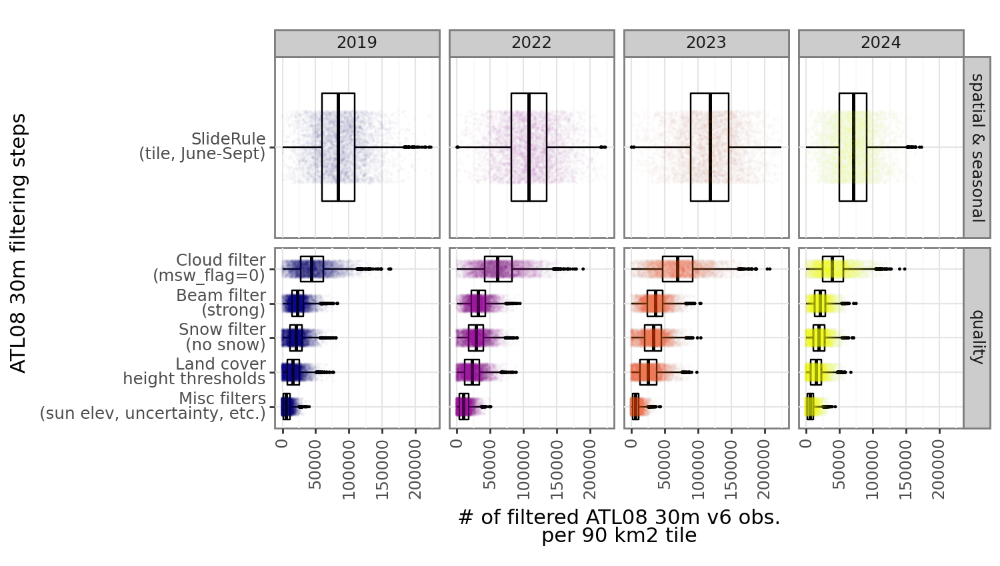

<Figure Size: (750 x 425)>

In [188]:
atl08_meta_df_m['variable'] = atl08_meta_df_m['variable'].cat.rename_categories({'sliderule': 'SlideRule\n(tile, June-Sept)', 'msw_flag=0': 'Cloud filter\n(msw_flag=0)', 
                                                                                 'beam_type=strong': 'Beam filter\n(strong)', 'snowcover=1': 'Snow filter\n(no snow)', 'h_can threshold (lc)':'Land cover\nheight thresholds',
                                                                                 'misc thresholds': 'Misc filters\n(sun elev, uncertainty, etc.)',
                                                                                'pct_reduct_qual_filt': '% reduction'})



(
    ggplot(atl08_meta_df_m[atl08_meta_df_m.filt_type != 'Filter summary'], aes(x='variable', y='value', color='year'))
    #+ geom_bin2d()
    + geom_boxplot(outlier_size=0, color='black')
    #+ geom_point(alpha=0.01, size=0.1)
    + geom_jitter(alpha=0.01, size=0.1, position = position_jitterdodge(jitter_width =1.5), show_legend=False)
    #+ geom_text(smry_m,  aes(x=0, y=0, label='value'))
    + scale_color_cmap_d(name = 'plasma')
    + theme_bw()
    + facet_grid('filt_type ~ year', scales='free_y')#, ncol=3)
    + scale_y_continuous(limits=(0,2.25e5))
    + labs(y='# of filtered ATL08 30m v6 obs.\nper 90 km2 tile', x='ATL08 30m filtering steps')
    + theme(figure_size=(7.5,4.25), axis_text_x = element_text(rotation=90))
    + coord_flip()
    + guides(  # new
        color=guide_legend(title="Year of ATL08")
    )

)

In [76]:
atl08_meta_df.to_csv('/projects/my-public-bucket/boreal_HLS_ATL08_metadata/data/ATL08_filt_metadata.csv')

## Stats on number of ATL08 v6 observations per tile

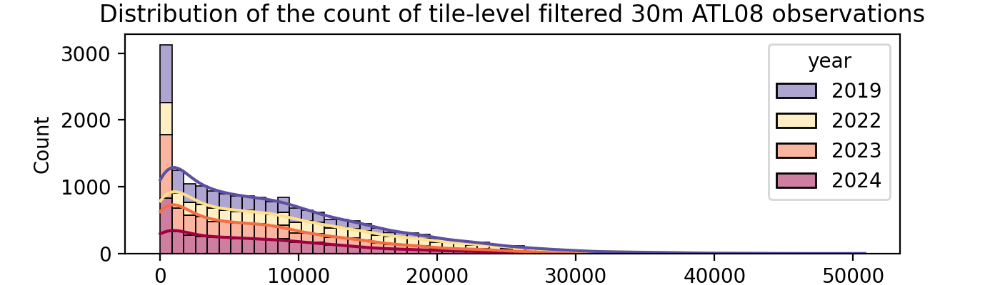

In [78]:
# stacked histogram
import matplotlib.pyplot as plt
# f = plt.figure(figsize=(7,2))
# ax = f.add_subplot(1,1,1)

f, ax = plt.subplots(1,1, figsize=(7,2))

# plot
import seaborn as sns

ax = sns.histplot(data=atl08_meta_df, ax=ax, stat="count", multiple="stack", #dodge
             x="seasonal_6-9", kde=True,
             palette="Spectral_r", hue="year", bins=60, legend=True )
ax.set_title(f"Distribution of the count of tile-level filtered 30m ATL08 observations")
ax.set_ylabel("Count")
ax.set_xlabel("# ATL08 30m obs.")
plt.show()

### Map Filtered Results after SlideRule ATL08 Re-Binning

Tiles :  
 - 1916 shows good diff between v6 and v5 ATL08 over low stature veg

In [395]:
importlib.reload(maplib_folium)

<module 'maplib_folium' from '/projects/code/icesat2_boreal/lib/maplib_folium.py'>

In [9]:
import maplib_folium
import branca.colormap as cm
pal_height_cmap = cm.LinearColormap(colors = ['black','#636363','#fc8d59','#fee08b','#ffffbf','#d9ef8b','#91cf60','#1a9850'], vmin=0, vmax=10)
pal_height_cmap.caption = 'Vegetation height from  ATL08 @ 30 m (h_can; rh98)'
pal_height_cmap

In [10]:
# # Get FOCAL_TILE_LIST from all that are processed
# FOCAL_TILE_LIST = boreal_tiles_ATL08_filt.tile_num.to_list()

# print(len(FOCAL_TILE_LIST))

In [408]:
# FOCAL_TILE_IDX = [i for i, tile_num in enumerate(FOCAL_TILE_LIST) if tile_num == 1842][0]
# FOCAL_TILE_IDX

# atl08_gdf_list = []
# for FOCAL_TILE in FOCAL_TILE_LIST[FOCAL_TILE_IDX:FOCAL_TILE_IDX+1]:
#     atl08_gdf_list.append(gpd.read_parquet(f'/projects/my-private-bucket/data/process_atl08_boreal/030m/2020/atl08_006_030m_2020_2020_06_09_filt_{FOCAL_TILE:05}.parquet'))

1707

In [11]:
FOCAL_TILE = 3175 #2913 #2668 #3009
YEAR_ATL08 = 2020

In [14]:
SEWARD_TILE_LIST = [3543,3544,3545, 
                   3637,3638,3639,
                   3732,3732,3733]

In [15]:
boreal_tiles[boreal_tiles.tile_num.isin(SEWARD_TILE_LIST)].explore()

In [16]:

atl08_list = []
for FOCAL_TILE in SEWARD_TILE_LIST:
    atl08_list.append( gpd.read_parquet(f'/projects/my-private-bucket/data/process_atl08_boreal/030m/{YEAR_ATL08}/atl08_006_030m_{YEAR_ATL08}_{YEAR_ATL08}_06_09_filt_{FOCAL_TILE:05}.parquet') )
atl08 = pd.concat(atl08_list)
atl08.shape

(100451, 44)

In [17]:
atl08.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 100451 entries, 44559 to 146914
Data columns (total 44 columns):
 #   Column                Non-Null Count   Dtype   
---  ------                --------------   -----   
 0   h_max_canopy          100451 non-null  float32 
 1   canopy_openness       100266 non-null  float32 
 2   solar_elevation       100451 non-null  float32 
 3   gnd_ph_count          100451 non-null  uint32  
 4   veg_ph_count          100451 non-null  uint32  
 5   snowcover             100451 non-null  uint8   
 6   landcover             100451 non-null  uint8   
 7   h_min_canopy          100451 non-null  float32 
 8   h_mean_canopy         100266 non-null  float32 
 9   segment_id            100451 non-null  uint32  
 10  cycle                 100451 non-null  uint16  
 11  rgt                   100451 non-null  uint16  
 12  gt                    100451 non-null  uint8   
 13  x_atc                 100451 non-null  float64 
 14  extent_id             100451 

In [18]:
def tile_reader(fn):
    tile_num = int(os.path.splitext(fn)[0].split('_')[-1])
    gdf = gpd.read_parquet(fn)
    gdf['tile_num'] = tile_num
    gdf['file'] = os.path.basename(fn)
    return gdf

def chunker(seq, size):
    return [seq[pos:pos + size] for pos in range(0, len(seq), size)]

In [19]:
smry_cnt_orig_list = []
smry_cnt_dropdups_list = []
atl08_gdf_list = []
maindir = '/projects/my-private-bucket/data/process_atl08_boreal/030m'

for FOCAL_TILE_LIST in chunker(boreal_tiles.tile_num.to_list(), 100):
#for FOCAL_TILE_LIST in [SEWARD_TILE_LIST]:
    for FOCAL_TILE in FOCAL_TILE_LIST:
        # Get the tindex for each each
        fn_list = glob.glob(f'{maindir}/**/atl08_006_030m_*_06_09_filt_*{FOCAL_TILE:05}.parquet') 
        if len(fn_list) > 0:
            atl08_gdf = pd.concat([tile_reader(fn) for fn in fn_list])
            #smry_cnt_orig_list.append(atl08_gdf.groupby(['file','tile_num','y']).aggregate(n_obs_year = ('tile_num', 'count')).reset_index())
            #smry_cnt_dropdups_list.append(atl08_gdf.drop_duplicates().groupby(['file','tile_num','y']).aggregate(n_obs_year = ('y', 'count')).reset_index())
    
            atl08_gdf_list.append(atl08_gdf)

OSError: [Errno 107] Failed to open local file '/projects/my-private-bucket/data/process_atl08_boreal/030m/2020/atl08_006_030m_2020_2020_06_09_filt_00004.parquet'. Detail: [errno 107] Transport endpoint is not connected

In [ ]:
atl08_gdf = pd.concat(atl08_gdf_list)
s1 = atl08_gdf.groupby(['file','tile_num','y']).aggregate(n_obs_year = ('tile_num', 'count')).reset_index()
s2 = atl08_gdf.drop_duplicates().groupby(['file','tile_num','y']).aggregate(n_obs_year = ('y', 'count')).reset_index()

sm = s1.merge(s2, how='outer', on=['file','tile_num','y'], suffixes=['_orig', '_nodups'])
sm['dif'] = sm.n_obs_year_orig - sm.n_obs_year_nodups
sm.head()

In [ ]:
atl08.groupby(['segment_landcover']).aggregate(n_obs_lc = ('segment_landcover', 'count')).reset_index()

In [ ]:
atl08.columns

Text(0.5, 0, 'Height from ATL08 30m obs.')

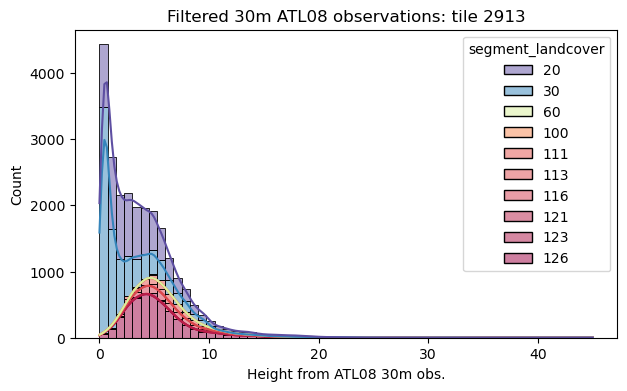

In [30]:
# stacked histogram
import matplotlib.pyplot as plt
f = plt.figure(figsize=(7,4))
ax = f.add_subplot(1,1,1)

# plot
import seaborn as sns

ax = sns.histplot(data=atl08[atl08.h_canopy > 0], ax=ax, stat="count", multiple="stack", #dodge
             x="h_canopy", kde=True,
             palette="Spectral_r", hue="segment_landcover", bins=60, legend=True )
ax.set_title(f"Filtered 30m ATL08 observations: tile {FOCAL_TILE}")
ax.set_ylabel("Count")
ax.set_xlabel("Height from ATL08 30m obs.")

#### Map relative uncertainty of h_canopy

In [56]:
# # Compute relative h_can_uncertainty
# atl08['h_can_uncert_rel'] = round(atl08['h_canopy_uncertainty'] / atl08['h_canopy'], 3)

In [ ]:
m = boreal_tiles[boreal_tiles.tile_num == FOCAL_TILE].boundary.explore(color='red', tiles=maplib_folium.tiler_basemap_image, attr=' ')
m = atl08.explore(m=m, column='h_canopy', cmap=pal_height_cmap, legend=True, vmax=20)
m = atl08.explore(m=m, column='h_can_uncert_rel', cmap='inferno', legend=True, vmax=1, style_kwds={"style_function":lambda x: {"radius":x["properties"]["h_canopy"]}})
folium.LayerControl().add_to(m)
m

In [65]:
ATL08_FILT_TINDEX_FN_DICT

{'c2020spring2022': 's3://maap-ops-workspace/shared/nathanmthomas/DPS_tile_lists/ATL08_filt/c2020/tile_atl08/ATL08_filt_tindex_master.csv',
 'c2020fall2022v1': 's3://maap-ops-workspace/shared/lduncanson/DPS_tile_lists/fall2022/with_gedi_rh/ATL08_filt_tindex_master.csv',
 'c2020fall2022v2': 's3://maap-ops-workspace/shared/lduncanson/DPS_tile_lists/fall2022/with_atl03_rh/ATL08_filt_tindex_master.csv',
 'c2020_v005': 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/ATL08/tile_atl08/c2020_v005/ATL08_filt_tindex_master.csv'}

# Comparitve mapping
## Map ATL08 v6 from sliderule

In [120]:
importlib.reload(maplib_folium)

<module 'maplib_folium' from '/projects/code/icesat2_boreal/lib/maplib_folium.py'>

In [ ]:
maplib_folium.map_tile_atl08([FOCAL_TILE], None, boreal_tiles, ATL08_filt_tindex_master_fn = atl08,
                             DO_NIGHT=False,
                  map_width = 600, map_height=1200, OVERVIEW_MAP= True,
                  max_AGB_display = 50, max_AGBSE_display = 20
                 )

## Map ATL08 v5 from Phase 2

In [84]:
# Here are Phase 2 filtered ATL08 tindex files
ATL08_FILT_TINDEX_FN_DICT

{'c2020spring2022': 's3://maap-ops-workspace/shared/nathanmthomas/DPS_tile_lists/ATL08_filt/c2020/tile_atl08/ATL08_filt_tindex_master.csv',
 'c2020fall2022v1': 's3://maap-ops-workspace/shared/lduncanson/DPS_tile_lists/fall2022/with_gedi_rh/ATL08_filt_tindex_master.csv',
 'c2020fall2022v2': 's3://maap-ops-workspace/shared/lduncanson/DPS_tile_lists/fall2022/with_atl03_rh/ATL08_filt_tindex_master.csv',
 'c2020_v005': 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/ATL08/tile_atl08/c2020_v005/ATL08_filt_tindex_master.csv'}

In [ ]:
maplib_folium.map_tile_atl08(FOCAL_TILE, None, boreal_tiles, ATL08_filt_tindex_master_fn = ATL08_FILT_TINDEX_FN_DICT['c2020spring2022'], DO_NIGHT=False,
                  map_width = 600, map_height=1200, OVERVIEW_MAP= True,
                  max_AGB_display = 50, max_AGBSE_display = 20
                 )

# Investigating ATL08 format differences from `Version 5` to `Version 6`

In [409]:
ATL08_FILT_TINDEX_FN_DICT

{'c2020spring2022': 's3://maap-ops-workspace/shared/nathanmthomas/DPS_tile_lists/ATL08_filt/c2020/tile_atl08/ATL08_filt_tindex_master.csv',
 'c2020fall2022v1': 's3://maap-ops-workspace/shared/lduncanson/DPS_tile_lists/fall2022/with_gedi_rh/ATL08_filt_tindex_master.csv',
 'c2020fall2022v2': 's3://maap-ops-workspace/shared/lduncanson/DPS_tile_lists/fall2022/with_atl03_rh/ATL08_filt_tindex_master.csv',
 'c2020_v005': 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/ATL08/tile_atl08/c2020_v005/ATL08_filt_tindex_master.csv',
 '2019': 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/ATL08/extract_atl08_covars/2019/ATL08_filt_tindex_master.csv',
 '2020': 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/ATL08/extract_atl08_covars/2020/ATL08_filt_tindex_master.csv',
 '2021': None,
 '2022': 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/ATL08/extract_atl08_covars/2022/ATL08_filt_tindex_master.csv',
 '2023': 's3://maap-ops-workspace/shared/montesano/DPS_tile_list

In [419]:
# v5 tindex
ATL08v5_tindex_2020 = pd.read_csv(ATL08_FILT_TINDEX_FN_DICT['c2020spring2022'])
# v6 tindex
ATL08v6_tindex_2020 = pd.read_csv(ATL08_FILT_TINDEX_FN_DICT['2020'])

In [411]:
# Check these tiles
CHECK_TILES = [2815,2816]

In [425]:
# Get the paths of those check tiles
v5_check_tile_fn_list = ATL08v5_tindex_2020[ATL08v5_tindex_2020.tile_num.isin(CHECK_TILES)].s3_path.to_list()
v6_check_tile_fn_list = ATL08v6_tindex_2020[ATL08v6_tindex_2020.tile_num.isin(CHECK_TILES)].s3_path.to_list()

### `Version 6` tiled/filtered/extracted-covars ATL08 parquets:
1. have more columns (SlideRule gave us more ATL08 cols, and we left them there for use later)  
2. have varying columns arrangements (but consistent column names)  
3. have inconsistent number of fields from SlideRule  (elaboration a few chunks below) 
4. have some columns named differently from `Version 5`  

These is annoying differences from the `Version 5` counterparts, but shouldnt be a problem, b/c downstream we select the column names we need to AGB modeling

In [414]:
v6_chk_1 = gpd.read_parquet(v6_check_tile_fn_list[0])
v6_chk_1.columns

Index(['extent_id', 'spot', 'gnd_ph_count', 'segment_id', 'h_te_median',
       'snowcover', 'h_max_canopy', 'canopy_openness', 'rgt', 'h_mean_canopy',
       'cycle', 'solar_elevation', 'veg_ph_count', 'h_canopy', 'x_atc', 'gt',
       'h_min_canopy', 'ph_count', 'landcover', 'geometry', 'h_dif_ref',
       'msw_flag', 'sigma_topo', 'segment_landcover', 'segment_snowcover',
       'rh25', 'rh50', 'rh60', 'rh70', 'rh75', 'rh80', 'rh85', 'rh90', 'rh95',
       'h_canopy_uncertainty', 'segment_cover', 'h_te_uncertainty', 'y', 'm',
       'd', 'doy', 'beam_type', 'elevation', 'slope', 'tsri', 'tpi',
       'slopemask', 'Blue', 'Green', 'Red', 'NIR', 'SWIR', 'SWIR2', 'NDVI',
       'SAVI', 'MSAVI', 'NDMI', 'EVI', 'NBR', 'NBR2', 'TCB', 'TCG', 'TCW',
       'ValidMask', 'Xgeo', 'Ygeo', 'JulianDate', 'yearDate',
       'vv_median_frozen', 'vh_median_frozen', 'vv_median_summer',
       'vh_median_summer', 'vv_median_shoulder', 'vh_median_shoulder',
       'n_frozen', 'n_summer', 'n_shoulder'],

In [415]:
v6_chk_2 = gpd.read_parquet(v6_check_tile_fn_list[1])
v6_chk_2.columns

Index(['h_max_canopy', 'spot', 'solar_elevation', 'h_te_median', 'h_canopy',
       'segment_id', 'cycle', 'x_atc', 'gt', 'rgt', 'canopy_openness',
       'gnd_ph_count', 'h_mean_canopy', 'ph_count', 'extent_id',
       'h_min_canopy', 'snowcover', 'landcover', 'veg_ph_count', 'geometry',
       'binsize', 'num_bins', 'h_dif_ref', 'msw_flag', 'sigma_topo',
       'segment_landcover', 'segment_snowcover', 'rh25', 'rh50', 'rh60',
       'rh70', 'rh75', 'rh80', 'rh85', 'rh90', 'rh95', 'h_canopy_uncertainty',
       'segment_cover', 'h_te_uncertainty', 'y', 'm', 'd', 'doy', 'beam_type',
       'elevation', 'slope', 'tsri', 'tpi', 'slopemask', 'Blue', 'Green',
       'Red', 'NIR', 'SWIR', 'SWIR2', 'NDVI', 'SAVI', 'MSAVI', 'NDMI', 'EVI',
       'NBR', 'NBR2', 'TCB', 'TCG', 'TCW', 'ValidMask', 'Xgeo', 'Ygeo',
       'JulianDate', 'yearDate', 'vv_median_frozen', 'vh_median_frozen',
       'vv_median_summer', 'vh_median_summer', 'vv_median_shoulder',
       'vh_median_shoulder', 'n_frozen', 'n_

### Inconsistent number of columns from SlideRule

For some unknown, SlideRule-related reason, some `Version 6` ATL08 have 2 additional, unnecessary fields

this could mess up column indexing - should identify columns explicitly with their names

In [417]:
print(len(v6_chk_1.columns))
print(len(v6_chk_2.columns))

77
79


In [418]:
set(v6_chk_1.columns).symmetric_difference(set(v6_chk_2.columns))

{'binsize', 'num_bins'}

### `Version 5` tiled/filtered/extracted-covars ATL08 csvs have names that are sometime different than their `Version 6` counterparts
but these are NOT the covar field names (from topo, HLS, S1) - so this difference shouldnt matter  
example:  
v5 name = `sol_el`  
v6 name = `solar_elevation`

In [77]:
v5_chk_1 = pd.read_csv(v5_check_tile_fn_list[0])
v5_chk_1.columns

Index(['lon', 'lat', 'rh25', 'rh50', 'rh60', 'rh70', 'rh75', 'rh80', 'rh90',
       'h_can', 'h_max_can', 'ter_slp', 'h_te_best', 'seg_landcov', 'sol_el',
       'y', 'm', 'doy', 'seg_cover', 'geometry', 'elevation', 'slope', 'tsri',
       'tpi', 'slopemask', 'Blue', 'Green', 'Red', 'NIR', 'SWIR', 'SWIR2',
       'NDVI', 'SAVI', 'MSAVI', 'NDMI', 'EVI', 'NBR', 'NBR2', 'TCB', 'TCG',
       'TCW', 'ValidMask', 'Xgeo', 'Ygeo', 'JulianDate', 'yearDate'],
      dtype='object')

## Example: merge neighbors

In [11]:
YEAR_ATL08 = 2020

In [15]:
TILE_NUM = 1613
f'/projects/my-public-bucket/DPS_tile_lists/ATL08/extract_atl08_covars/{YEAR_ATL08}/ATL08_filt_extract_tindex_master.csv'

'/projects/my-public-bucket/DPS_tile_lists/ATL08/extract_atl08_covars/2020/ATL08_filt_extract_tindex_master.csv'

In [19]:
args = f'-in_tile_num {TILE_NUM} \
-in_tile_fn {boreal_tile_index_path} \
-in_tile_field tile_num \
-csv_list_fn s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/ATL08/extract_atl08_covars/2020/ATL08_filt_tindex_master.csv \
-DPS_DATA_USER montesano \
-out_dir /projects/tmp'

In [20]:
!python /projects/code/icesat2_boreal/lib/merge_neighbors_atl08.py $args

Neighbor tile ids for tile 1613: [1556, 1557, 1558, 1612, 1614, 1669, 1670, 1671]
# of neighbor tiles: 8
Reading ATL08 tile index: s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/ATL08/extract_atl08_covars/2020/ATL08_filt_tindex_master.csv
Found: s3://maap-ops-workspace/montesano/dps_output/run_extract_atl08_covars/extract_atl08_covars/2020/2024/02/28/07/22/51/681947/atl08_006_030m_2020_2020_06_09_filt_covars_001613.parquet
# of neighbor tiles with filtered ATL08 geodataframes with extracted covariates: 8 
Wrote out: /projects/tmp/atl08_006_030m_2020_2020_06_09_filt_covars_merge_neighbors_001613.parquet
Focal tile + neighbors shape: (120110, 79)
Adding lat, lon fields & dropping geometry field for CSV output...
Wrote out: /projects/tmp/atl08_006_030m_2020_2020_06_09_filt_covars_merge_neighbors_001613.csv


In [21]:
atl08_merge_neighbors = gpd.read_parquet(f'/projects/my-public-bucket/local_output/atl08_006_030m_2020_2020_06_09_filt_covars_merge_neighbors_{TILE_NUM:06}.parquet')
atl08_merge_neighbors.shape

(120110, 79)

In [40]:
atl08_merge_neighbors[atl08_merge_neighbors.NDVI == -9999].shape

(1031, 79)

In [41]:
atl08_extract = gpd.read_parquet('s3://maap-ops-workspace/montesano/dps_output/run_extract_atl08_covars/extract_atl08_covars/2020/2024/02/28/07/22/51/681947/atl08_006_030m_2020_2020_06_09_filt_covars_001613.parquet')
atl08_extract.shape

(9046, 77)

In [42]:
atl08_extract[atl08_extract.NDVI == -9999].shape

(40, 77)

In [24]:
import tileslib

Registering the mosaic with Titiler...
{'id': 'd41c4a11-0f79-4ddb-8b9b-2381d165e51b', 'links': [{'href': 'https://titiler.maap-project.org/mosaics/d41c4a11-0f79-4ddb-8b9b-2381d165e51b', 'rel': 'self', 'type': 'application/json', 'title': 'Self'}, {'href': 'https://titiler.maap-project.org/mosaics/d41c4a11-0f79-4ddb-8b9b-2381d165e51b/mosaicjson', 'rel': 'mosaicjson', 'type': 'application/json', 'title': 'MosaicJSON'}, {'href': 'https://titiler.maap-project.org/mosaics/d41c4a11-0f79-4ddb-8b9b-2381d165e51b/tilejson.json', 'rel': 'tilejson', 'type': 'application/json', 'title': 'TileJSON'}, {'href': 'https://titiler.maap-project.org/mosaics/d41c4a11-0f79-4ddb-8b9b-2381d165e51b/tiles/{z}/{x}/{y}', 'rel': 'tiles', 'type': 'application/json', 'title': 'Tiles'}, {'href': 'https://titiler.maap-project.org/mosaics/d41c4a11-0f79-4ddb-8b9b-2381d165e51b/WMTSCapabilities.xml', 'rel': 'wmts', 'type': 'application/json', 'title': 'WMTS'}]}
Registering the mosaic with Titiler...
{'id': 'd44daccc-1ec1-4

In [36]:
tileslib.HLS_NDVI_TILES_LAYER_DICT['2020']['layer'].tiles

'https://titiler.maap-project.org/mosaics/48282962-c503-42a0-b464-3811879daa15/tiles/{z}/{x}/{y}@1x?rescale=0.3%2C+0.8&bidx=7&colormap_name=hsv'

In [44]:
boreal_tiles = gpd.read_file(boreal_tile_index_path)

In [46]:
atl08_merge_neighbors[atl08_merge_neighbors.NDVI == -9999].explore(
    m=boreal_tiles[boreal_tiles.tile_num == TILE_NUM].explore(tiles='ESRIWorldImagery'),
    #tiles=tileslib.HLS_NDVI_TILES_LAYER_DICT['2020']['layer'].tiles, attr=' '
)

In [49]:
atl08_merge_neighbors.columns

Index(['extent_id', 'canopy_openness', 'h_te_median', 'rgt', 'h_max_canopy',
       'gnd_ph_count', 'solar_elevation', 'snowcover', 'h_mean_canopy',
       'segment_id', 'gt', 'h_min_canopy', 'spot', 'ph_count', 'veg_ph_count',
       'landcover', 'cycle', 'h_canopy', 'x_atc', 'geometry', 'num_bins',
       'binsize', 'h_dif_ref', 'msw_flag', 'sigma_topo', 'segment_landcover',
       'segment_snowcover', 'rh25', 'rh50', 'rh60', 'rh70', 'rh75', 'rh80',
       'rh85', 'rh90', 'rh95', 'h_canopy_uncertainty', 'segment_cover',
       'h_te_uncertainty', 'y', 'm', 'd', 'doy', 'beam_type', 'elevation',
       'slope', 'tsri', 'tpi', 'slopemask', 'Blue', 'Green', 'Red', 'NIR',
       'SWIR', 'SWIR2', 'NDVI', 'SAVI', 'MSAVI', 'NDMI', 'EVI', 'NBR', 'NBR2',
       'TCB', 'TCG', 'TCW', 'ValidMask', 'Xgeo', 'Ygeo', 'JulianDate',
       'yearDate', 'vv_median_frozen', 'vh_median_frozen', 'vv_median_summer',
       'vh_median_summer', 'vv_median_shoulder', 'vh_median_shoulder',
       'n_frozen', 'n_

In [50]:
atl08_merge_neighbors[['landcover','segment_landcover']][0:20]

,landcover,segment_landcover
35086,111,111
35090,111,111
35094,111,111
35098,111,111
35102,111,111
35106,111,111
35110,111,111
35114,111,111
35118,111,111
35123,111,111


In [ ]:
m = boreal_tiles[boreal_tiles.tile_num == TILE_NUM].boundary.explore(color='red', tiles=maplib_folium.tiler_basemap_image, attr=' ')
m = atl08_merge_neighbors.sample(frac=0.01).explore(m=m, column='h_canopy', cmap=pal_height_cmap, legend=True, vmax=20)
folium.LayerControl().add_to(m)
m

### View many points with lonboard

In [51]:
from lonboard import viz

viz(atl08_merge_neighbors)

/opt/conda/envs/pangeo/lib/python3.10/site-packages/lonboard/_geoarrow/ops/reproject.py:97: UserWarning: Input being reprojected to EPSG:4326 CRS
  warnings.warn("Input being reprojected to EPSG:4326 CRS")


Map(basemap_style=<CartoBasemap.DarkMatter: 'https://basemaps.cartocdn.com/gl/dark-matter-gl-style/style.json'…

In [53]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import shapely
from palettable.colorbrewer.diverging import BrBG_10

from lonboard import Map, ScatterplotLayer
from lonboard.colormap import apply_continuous_cmap

In [54]:
layer = ScatterplotLayer.from_geopandas(atl08_merge_neighbors)
m = Map(layer)
m

/opt/conda/envs/pangeo/lib/python3.10/site-packages/lonboard/_geoarrow/ops/reproject.py:97: UserWarning: Input being reprojected to EPSG:4326 CRS
  warnings.warn("Input being reprojected to EPSG:4326 CRS")


Map(layers=[ScatterplotLayer(table=pyarrow.Table
extent_id: uint64
canopy_openness: float
h_te_median: float
r…